# AnalystLab Africa – Week 3 Assignment

# TRACK B: DATA SCIENCE
# Assignment Title: Healthcare Operations: Statistical Investigation & Insight Discovery



# **Objective**
#Investigate a healthcare operations problem using exploratory data analysis, statistical reasoning, and evidence-based interpretation.

# Task 1: Define the research question

**Step 1: Define the research question**
### **1.1 Proposed research topic**
Statistical Investigation of the Relationship Between Hospital Encounter Duration and Recorded Claim Costs

### **1.2 Research question**
Is there a statistically significant association between hospital encounter duration and recorded total claim costs?
### **1.3 Background and problem statement**
Healthcare organisations need to understand how the duration of patient encounters relates to the costs recorded for those encounters. Understanding this relationship can help hospital administrators investigate cost patterns, review resource utilisation, and identify areas that may require further operational assessment.

However, longer encounters do not necessarily cause higher costs. Differences in encounter class, procedures performed, patient characteristics, and other factors may also influence recorded costs.

This investigation will examine the relationship between encounter duration and total claim costs using the historical healthcare datasets provided by AnalystLab Africa.

### **1.4 Aim**
To investigate the relationship between hospital encounter duration and recorded total claim costs using exploratory data analysis and appropriate statistical methods.

### **1.5 Specific objectives**
1. Assess the quality and suitability of the encounter dataset for the proposed investigation.
2. Examine the distribution of encounter duration and total claim costs.
3. Investigate the relationship between encounter duration and recorded claim costs.
4. Test whether recorded claim costs differ significantly between short-duration and long-duration encounters.
5. Interpret the findings and develop evidence-based recommendations for healthcare operations.

### **1.6 Variables required**

###**Variable  and Purpose**
- Encounter ID:	 Identify individual   encounter records
- Encounter start date and time:	Establish the beginning of an encounter
- Encounter end date and time: 	Establish the end of an encounter
- Total claim cost:	Measure the recorded cost associated with an encounter
- Encounter class:	Examine whether cost patterns differ across encounter types
- Patient ID:	Identify repeated encounters belonging to the same patient

## **Task 2: Conduct exploratory data analysis**

In [20]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import csv
from datetime import datetime

In [11]:
#load datasets
df_encounters = pd.read_csv('/content/encounters.csv')
df_patients = pd.read_csv('/content/patients.csv')
df_procedures = pd.read_csv('/content/procedures.csv')
df_payers = pd.read_csv('/content/payers.csv')
df_organizations = pd.read_csv('/content/organizations.csv')
df_data_dictionary = pd.read_csv('/content/data_dictionary.csv')

In [7]:
# inpect df_encounters dataset
# display first five records
display(df_encounters.head(5))
print("-" * 100)

#check number of rows and columns
print("Number of rows and columnns", df_encounters.shape)

#inpect column names and dataypes
print("-" * 100)
print("Column names and datatypes", df_encounters.info())

#generate discriptive statistics
print("-" * 100)
print("Descriptive statistics", df_encounters.describe())

#check for missing values
print("-" * 100)
print("Check Missing values", df_encounters.isnull().sum)

3#check for duplicates
print("-" * 100)
print("Duplicate values", df_encounters.duplicated().sum())

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,32c84703-2481-49cd-d571-3899d5820253,2011-01-02T09:26:36Z,2011-01-02T12:58:36Z,3de74169-7f67-9304-91d4-757e0f3a14d2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,ambulatory,185347001,Encounter for problem (procedure),85.55,1018.02,0.00,NaN,NaN
1,c98059da-320a-c0a6-fced-c8815f3e3f39,2011-01-03T05:44:39Z,2011-01-03T06:01:42Z,d9ec2e44-32e9-9148-179a-1653348cc4e2,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,308335008,Patient encounter procedure,142.58,2619.36,0.00,NaN,NaN
2,4ad28a3a-2479-782b-f29c-d5b3f41a001e,2011-01-03T14:32:11Z,2011-01-03T14:47:11Z,73babadf-5b2b-fee7-189e-6f41ff213e01,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,outpatient,185349003,Encounter for check up (procedure),85.55,461.59,305.27,NaN,NaN
3,c3f4da61-e4b4-21d5-587a-fbc89943bc19,2011-01-03T16:24:45Z,2011-01-03T16:39:45Z,3b46a0b7-0f34-9b9a-c319-ace4a1f58c0b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,wellness,162673000,General examination of patient (procedure),136.80,1784.24,0.00,NaN,NaN
4,a9183b4f-2572-72ea-54c2-b3cd038b4be7,2011-01-03T17:36:53Z,2011-01-03T17:51:53Z,fa006887-d93c-d302-8b89-f3c25f88c0e1,d78e84ec-30aa-3bba-a33a-f29a3a454662,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,ambulatory,390906007,Follow-up encounter,85.55,234.72,0.00,55822004.0,Hyperlipidemia


----------------------------------------------------------------------------------------------------
Number of rows and columnns (27891, 14)
----------------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27891 entries, 0 to 27890
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   27891 non-null  object 
 1   START                27891 non-null  object 
 2   STOP                 27891 non-null  object 
 3   PATIENT              27891 non-null  object 
 4   ORGANIZATION         27891 non-null  object 
 5   PAYER                27891 non-null  object 
 6   ENCOUNTERCLASS       27891 non-null  object 
 7   CODE                 27891 non-null  int64  
 8   DESCRIPTION          27891 non-null  object 
 9   BASE_ENCOUNTER_COST  27891 non-null  float64
 10  TOTAL_CLAIM_COST     27891 non-null  float64

**Key Findings**
- Claim costs vary widely: Most claims are relatively low, with 75% below $1,412.53, but a few very expensive cases push the average up to $3,639.68. The highest claim is $641,882.70.
- Base visit fees are fairly consistent: Base encounter costs average $116.18, suggesting that the standard fee for a visit is relatively stable.
- Other factors drive total costs: Procedures, medications and length of stay likely contribute more to total claim costs than the basic visit fee.
- Payer coverage is often low: The median coverage is just $28.44, and at least 25% of encounters have no recorded payer coverage. However, some claims receive substantial coverage, reaching $247,751.42.

### Overall: Most healthcare encounters are relatively inexpensive, but a small number of high-cost cases significantly increase total spending

In [8]:
# inpect df_patients dataset

# display first five records
display(df_patients.head(5))
print("-" * 100)

#check number of rows and columns
print("Number of rows and columnns", df_patients.shape)

#inpect column names and dataypes
print("-" * 100)
print("Column names and datatypes", df_patients.info())

#generate discriptive statistics
print("-" * 100)
print("Descriptive statistics", df_patients.describe())

#check for missing values
print("-" * 100)
print("Check Missing values", df_patients.isnull().sum)

3#check for duplicates
print("-" * 100)
print("Duplicate values", df_patients.duplicated().sum())

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,5605b66b-e92d-c16c-1b83-b8bf7040d51f,1977-03-19,NaN,Mrs.,Nikita578,Erdman779,NaN,Leannon79,M,white,nonhispanic,F,Wakefield Massachusetts US,510 Little Station Unit 69,Quincy,Massachusetts,Norfolk County,2186.0,42.290937,-70.975503
1,6e5ae27c-8038-7988-e2c0-25a103f01bfa,1940-02-19,NaN,Mr.,Zane918,Hodkiewicz467,NaN,NaN,M,white,nonhispanic,M,Brookline Massachusetts US,747 Conn Throughway,Boston,Massachusetts,Suffolk County,2135.0,42.308831,-71.063162
2,8123d076-0886-9007-e956-d5864aa121a7,1958-06-04,NaN,Mr.,Quinn173,Marquardt819,NaN,NaN,M,white,nonhispanic,M,Gardner Massachusetts US,816 Okuneva Extension Apt 91,Quincy,Massachusetts,Norfolk County,2170.0,42.265177,-70.967085
3,770518e4-6133-648e-60c9-071eb2f0e2ce,1928-12-25,2017-09-29,Mr.,Abel832,Smitham825,NaN,NaN,M,white,hispanic,M,Randolph Massachusetts US,127 Cole Way Unit 95,Boston,Massachusetts,Suffolk County,2118.0,42.334304,-71.066801
4,f96addf5-81b9-0aab-7855-d208d3d352c5,1928-12-25,2014-02-23,Mr.,Edwin773,Labadie908,NaN,NaN,M,white,hispanic,M,Stow Massachusetts US,976 Ziemann Gateway,Boston,Massachusetts,Suffolk County,2125.0,42.346771,-71.058813


----------------------------------------------------------------------------------------------------
Number of rows and columnns (974, 20)
----------------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 974 entries, 0 to 973
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Id          974 non-null    object 
 1   BIRTHDATE   974 non-null    object 
 2   DEATHDATE   154 non-null    object 
 3   PREFIX      974 non-null    object 
 4   FIRST       974 non-null    object 
 5   LAST        974 non-null    object 
 6   SUFFIX      21 non-null     object 
 7   MAIDEN      386 non-null    object 
 8   MARITAL     973 non-null    object 
 9   RACE        974 non-null    object 
 10  ETHNICITY   974 non-null    object 
 11  GENDER      974 non-null    object 
 12  BIRTHPLACE  974 non-null    object 
 13  ADDRESS     974 non-null    object 

- Dataset size: Covers 974 unique patients across 20 demographic and geographic variables.
- Data completeness: Most fields are complete, with marital status almost fully recorded. Some names and ZIP codes are missing, but complete location coordinates support geographic analysis.
- Geographic reach: Patients are mainly concentrated in the Boston, Massachusetts metropolitan area.

### Overall:The dataset is well-structured for demographic and geographic analysis, with minor missing data that may require attention.

In [9]:
# inpect df_procedures dataset

# display first five records
display(df_procedures.head(5))
print("-" * 100)

#check number of rows and columns
print("Number of rows and columnns", df_procedures.shape)

#inpect column names and dataypes
print("-" * 100)
print("Column names and datatypes", df_procedures.info())

#generate discriptive statistics
print("-" * 100)
print("Descriptive statistics", df_procedures.describe())

#check for missing values
print("-" * 100)
print("Check Missing values", df_procedures.isnull().sum)

3#check for duplicates
print("-" * 100)
print("Duplicate values", df_procedures.duplicated().sum())

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
0,2011-01-02T09:26:36Z,2011-01-02T12:58:36Z,3de74169-7f67-9304-91d4-757e0f3a14d2,32c84703-2481-49cd-d571-3899d5820253,265764009,Renal dialysis (procedure),903,NaN,NaN
1,2011-01-03T05:44:39Z,2011-01-03T06:01:42Z,d9ec2e44-32e9-9148-179a-1653348cc4e2,c98059da-320a-c0a6-fced-c8815f3e3f39,76601001,Intramuscular injection,2477,NaN,NaN
2,2011-01-04T14:49:55Z,2011-01-04T15:04:55Z,d856d6e6-4c98-e7a2-129b-44076c63d008,2cfd4ddd-ad13-fe1e-528b-15051cea2ec3,703423002,Combined chemotherapy and radiation therapy (p...,11620,363406005.0,Malignant tumor of colon
3,2011-01-05T04:02:09Z,2011-01-05T04:17:09Z,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,17966936-0878-f4db-128b-a43ae10d0878,173160006,Diagnostic fiberoptic bronchoscopy (procedure),9796,162573006.0,Suspected lung cancer (situation)
4,2011-01-05T12:58:36Z,2011-01-05T16:42:36Z,3de74169-7f67-9304-91d4-757e0f3a14d2,9de5f0b0-4ba4-ce6f-45fb-b55c202f31a5,265764009,Renal dialysis (procedure),1255,NaN,NaN


----------------------------------------------------------------------------------------------------
Number of rows and columnns (47701, 9)
----------------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47701 entries, 0 to 47700
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   START              47701 non-null  object 
 1   STOP               47701 non-null  object 
 2   PATIENT            47701 non-null  object 
 3   ENCOUNTER          47701 non-null  object 
 4   CODE               47701 non-null  int64  
 5   DESCRIPTION        47701 non-null  object 
 6   BASE_COST          47701 non-null  int64  
 7   REASONCODE         10756 non-null  float64
 8   REASONDESCRIPTION  10756 non-null  object 
dtypes: float64(1), int64(2), object(6)
memory usage: 3.3+ MB
Column names and datatypes None
-----------------------------

- Procedure volume: 47,701 procedures across 27,891 encounters, indicating multiple procedures per encounter.
- Costs: Median cost is $431, but a few expensive procedures push the average to $2,212.
- Missing data: Only 22.5% of procedures have recorded clinical reasons.

### Overall: High procedure volume, variable costs, and missing clinical reasons may limit analysis.

In [10]:
# inpect df_payers dataset

# display first five records
display(df_payers.head(5))
print("-" * 100)

#check number of rows and columns
print("Number of rows and columnns", df_payers.shape)

#inpect column names and dataypes
print("-" * 100)
print("Column names and datatypes", df_payers.info())

#generate discriptive statistics
print("-" * 100)
print("Descriptive statistics", df_payers.describe())

#check for missing values
print("-" * 100)
print("Check Missing values", df_payers.isnull().sum)

3#check for duplicates
print("-" * 100)
print("Duplicate values", df_payers.duplicated().sum())

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323
1,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare,7500 Security Blvd,Baltimore,MD,21244.0,1-800-633-4227
2,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,Medicaid,7500 Security Blvd,Baltimore,MD,21244.0,1-877-267-2323
3,d47b3510-2895-3b70-9897-342d681c769d,Humana,500 West Main St,Louisville,KY,40018.0,1-844-330-7799
4,6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield,Michigan Plaza,Chicago,IL,60007.0,1-800-262-2583


----------------------------------------------------------------------------------------------------
Number of rows and columnns (10, 7)
----------------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   10 non-null     object 
 1   NAME                 10 non-null     object 
 2   ADDRESS              9 non-null      object 
 3   CITY                 9 non-null      object 
 4   STATE_HEADQUARTERED  9 non-null      object 
 5   ZIP                  9 non-null      float64
 6   PHONE                9 non-null      object 
dtypes: float64(1), object(6)
memory usage: 692.0+ bytes
Column names and datatypes None
----------------------------------------------------------------------------------------------------
Descriptive statistic

- Payer network: 10 insurance programs across 7 variables, including Medicare, Medicaid and Humana.
- Missing data: Most records are complete, but the uninsured entry lacks contact and location details.
- Geographic spread: Payers are headquartered across different regions, unlike the Boston-centered patient population.
#### Overall: The dataset captures a small, geographically diverse payer network with minor missing data.

In [12]:
# inpect df_organizations dataset

# display first five records
display(df_organizations.head(5))
print("-" * 100)

#check number of rows and columns
print("Number of rows and columnns", df_organizations.shape)

#inpect column names and dataypes
print("-" * 100)
print("Column names and datatypes", df_organizations.info())

#generate discriptive statistics
print("-" * 100)
print("Descriptive statistics", df_organizations.describe())

#check for missing values
print("-" * 100)
print("Check Missing values", df_organizations.isnull().sum)

3#check for duplicates
print("-" * 100)
print("Duplicate values", df_organizations.duplicated().sum())

,Id,NAME,ADDRESS,CITY,STATE,ZIP,LAT,LON
0,d78e84ec-30aa-3bba-a33a-f29a3a454662,MASSACHUSETTS GENERAL HOSPITAL,55 FRUIT STREET,BOSTON,MA,2114,42.362813,-71.069187


----------------------------------------------------------------------------------------------------
Number of rows and columnns (1, 8)
----------------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1 entries, 0 to 0
Data columns (total 8 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Id       1 non-null      object 
 1   NAME     1 non-null      object 
 2   ADDRESS  1 non-null      object 
 3   CITY     1 non-null      object 
 4   STATE    1 non-null      object 
 5   ZIP      1 non-null      int64  
 6   LAT      1 non-null      float64
 7   LON      1 non-null      float64
dtypes: float64(2), int64(1), object(5)
memory usage: 196.0+ bytes
Column names and datatypes None
----------------------------------------------------------------------------------------------------
Descriptive statistics           ZIP        LAT        LON
count     1.0   1.000000

- Dataset size: Contains 1 organization across 8 variables.
- Data completeness: All 8 columns are fully populated, with no missing values.
- Descriptive statistics: Limited because only one record is available.
- Duplicates: No duplicate records found.
#### Overall: The dataset is complete and clean but too small for meaningful statistical analysis.

In [13]:
# inpect df_data_dictionary dataset

# display first five records
display(df_data_dictionary.head(5))
print("-" * 100)

#check number of rows and columns
print("Number of rows and columnns", df_data_dictionary.shape)

#inpect column names and dataypes
print("-" * 100)
print("Column names and datatypes", df_data_dictionary.info())

#generate discriptive statistics
print("-" * 100)
print("Descriptive statistics", df_data_dictionary.describe())

#check for missing values
print("-" * 100)
print("Check Missing values", df_data_dictionary.isnull().sum)

3#check for duplicates
print("-" * 100)
print("Duplicate values", df_data_dictionary.duplicated().sum())

,Table,Field,Description
0,encounters,NaN,Patient encounter data
1,encounters,Id,Primary Key. Unique Identifier of the encounter.
2,encounters,Start,The date and time (iso8601 UTC Date (yyyy-MM-d...
3,encounters,Stop,The date and time (iso8601 UTC Date (yyyy-MM-d...
4,encounters,Patient,Foreign key to the Patient.


----------------------------------------------------------------------------------------------------
Number of rows and columnns (65, 3)
----------------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 65 entries, 0 to 64
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Table        65 non-null     object
 1   Field        60 non-null     object
 2   Description  65 non-null     object
dtypes: object(3)
memory usage: 1.7+ KB
Column names and datatypes None
----------------------------------------------------------------------------------------------------
Descriptive statistics            Table Field                  Description
count         65    60                           65
unique         5    40                           60
top     patients    Id  Foreign key to the Patient.
freq          23     4                            2

- Dataset size: 65 rows across 3 columns, documenting variables and descriptions.
- Missing fields: 5 blank entries, mainly representing table-level information.
- Uniqueness: 40 unique field names across 5 tables, with some identifiers reused.
#### Overall: The data dictionary provides a useful reference for understanding variables and linking datasets.

## Idenify outtliers

In [17]:
#perform outlier detection

def detect_outliers_iqr(df, column_name):
    q1 = df[column_name].quantile(0.25)
    q3 = df[column_name].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[(df[column_name] < lower_bound) | (df[column_name] > upper_bound)]

    print(f"--- Outlier Analysis for {column_name} ---")
    print(f"Q1 (25th percentile): {q1:.2f}")
    print(f"Q3 (75th percentile): {q3:.2f}")
    print(f"IQR: {iqr:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Total records: {len(df)}")
    print(f"Number of outliers: {len(outliers)} ({len(outliers)/len(df)*100:.2f}% of data)")
    if len(outliers) > 0:
        print(f"Outliers Min: {outliers[column_name].min():.2f} | Outliers Max: {outliers[column_name].max():.2f}\n")
    return outliers, lower_bound, upper_bound

# Analyze encounters claim cost
enc_outliers, enc_low, enc_high = detect_outliers_iqr(df_encounters, 'TOTAL_CLAIM_COST')

# Analyze procedures cost
proc_outliers, proc_low, proc_high = detect_outliers_iqr(df_procedures, 'BASE_COST')

--- Outlier Analysis for TOTAL_CLAIM_COST ---
Q1 (25th percentile): 142.58
Q3 (75th percentile): 1412.53
IQR: 1269.95
Lower Bound: -1762.35
Upper Bound: 3317.46
Total records: 27891
Number of outliers: 5316 (19.06% of data)
Outliers Min: 3322.73 | Outliers Max: 641882.70

--- Outlier Analysis for BASE_COST ---
Q1 (25th percentile): 431.00
Q3 (75th percentile): 966.00
IQR: 535.00
Lower Bound: -371.50
Upper Bound: 1768.50
Total records: 47701
Number of outliers: 9174 (19.23% of data)
Outliers Min: 1769.00 | Outliers Max: 289531.00



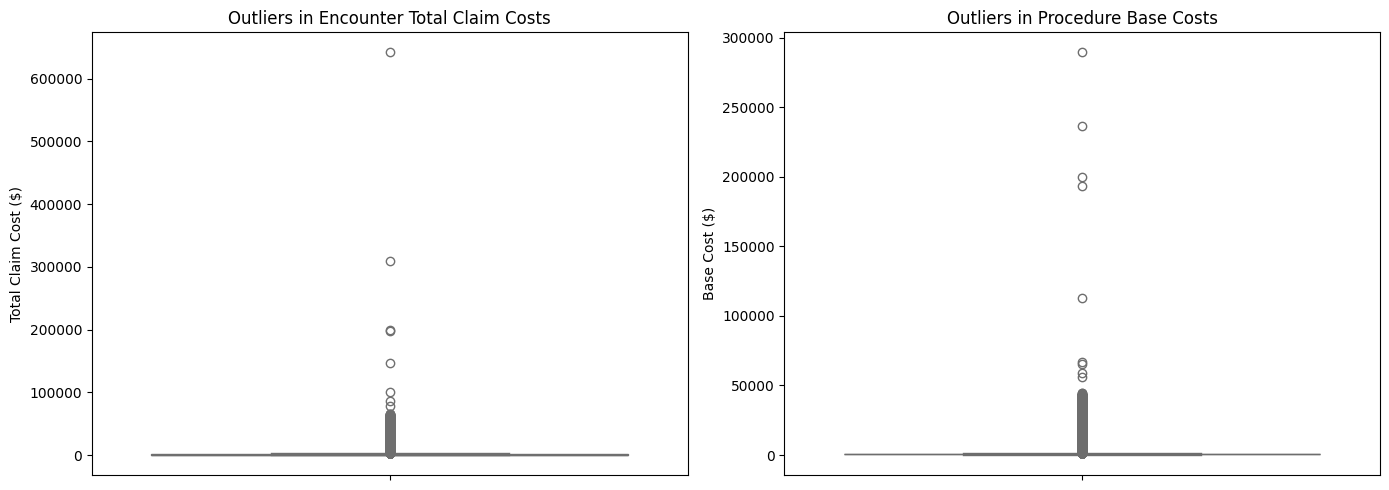

In [18]:
# Visualizing the distribution and outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(y=df_encounters['TOTAL_CLAIM_COST'], ax=axes[0], color='skyblue')
axes[0].set_title('Outliers in Encounter Total Claim Costs')
axes[0].set_ylabel('Total Claim Cost ($)')

sns.boxplot(y=df_procedures['BASE_COST'], ax=axes[1], color='salmon')
axes[1].set_title('Outliers in Procedure Base Costs')
axes[1].set_ylabel('Base Cost ($)')

plt.tight_layout()
plt.show()

- Claim costs: 5,316 encounters (19.06%) exceed the $3,317.46 outlier threshold, with costs reaching $641,882.70.
- Procedure costs: 9,174 procedures (19.23%) exceed the $1,768.50 threshold, reaching $289,531.
- Cost distribution: A few extremely expensive cases significantly increase overall costs.
#### Overall: Costs are highly skewed; median-based statistics and log transformations may provide more reliable analysis than averages.

## Five Appropriate visualisations.

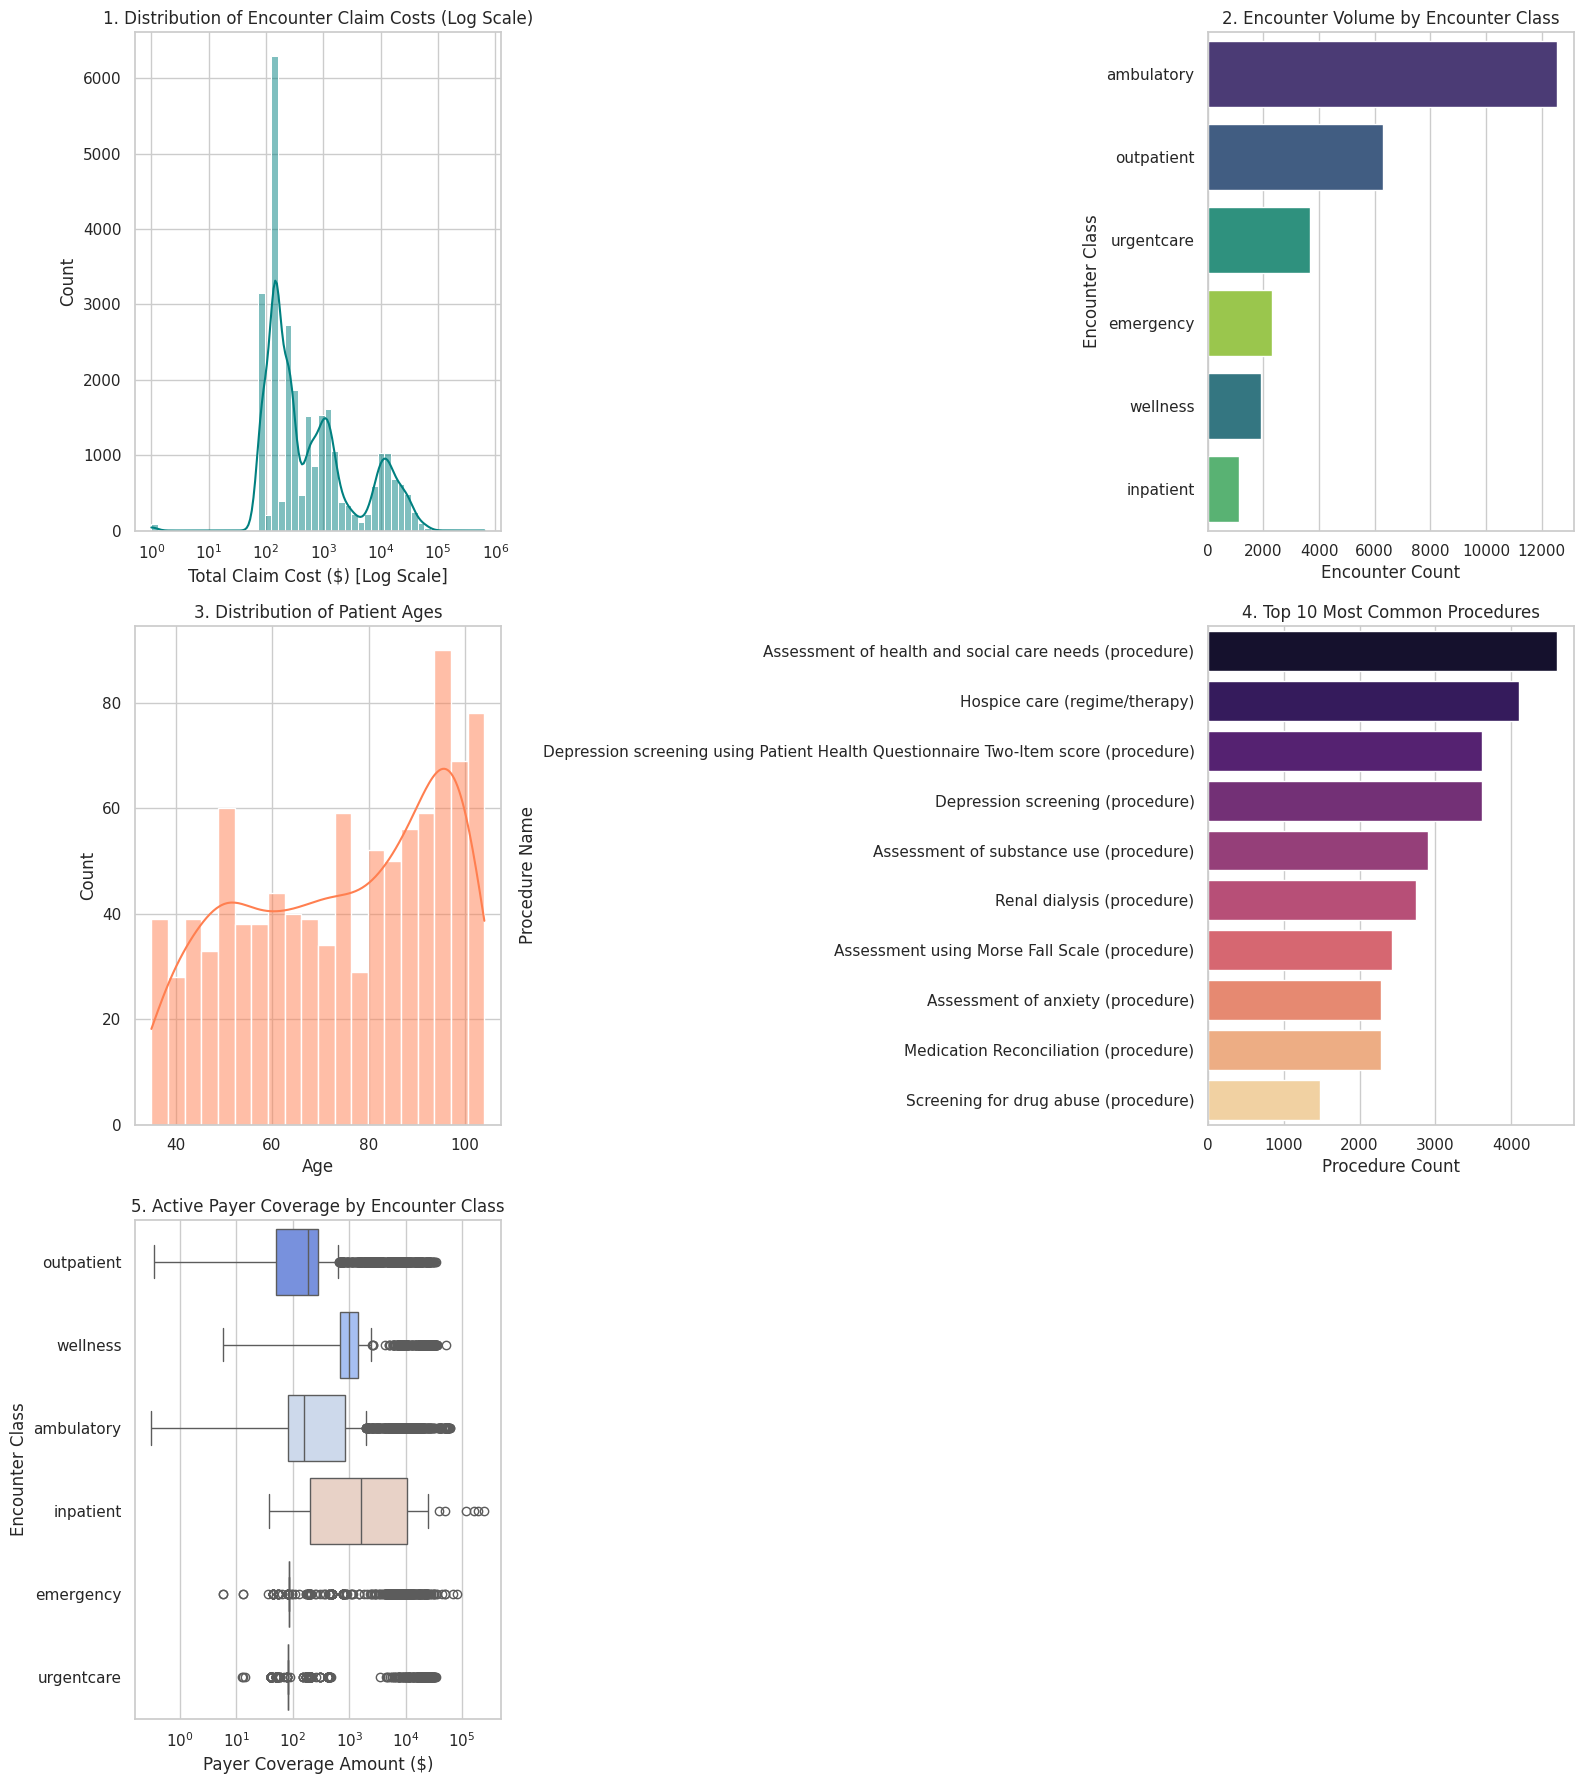

In [21]:

# Set seaborn aesthetic
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# 1. Distribution of Encounter Total Claim Costs (Log Scale to handle skew)
sns.histplot(df_encounters['TOTAL_CLAIM_COST'] + 1, bins=50, kde=True, ax=axes[0, 0], color='teal', log_scale=True)
axes[0, 0].set_title('1. Distribution of Encounter Claim Costs (Log Scale)')
axes[0, 0].set_xlabel('Total Claim Cost ($) [Log Scale]')
axes[0, 0].set_ylabel('Count')

# 2. Encounter Volume by Class
sns.countplot(data=df_encounters, y='ENCOUNTERCLASS', ax=axes[0, 1], order=df_encounters['ENCOUNTERCLASS'].value_counts().index, palette='viridis', hue='ENCOUNTERCLASS', legend=False)
axes[0, 1].set_title('2. Encounter Volume by Encounter Class')
axes[0, 1].set_xlabel('Encounter Count')
axes[0, 1].set_ylabel('Encounter Class')

# 3. Distribution of Patient Age
birth_years = pd.to_datetime(df_patients['BIRTHDATE'], errors='coerce').dt.year
current_year = datetime.now().year
patient_ages = current_year - birth_years
sns.histplot(patient_ages.dropna(), bins=20, kde=True, ax=axes[1, 0], color='coral')
axes[1, 0].set_title('3. Distribution of Patient Ages')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Count')

# 4. Top 10 Most Common Procedures
top_procedures = df_procedures['DESCRIPTION'].value_counts().head(10)
sns.barplot(x=top_procedures.values, y=top_procedures.index, ax=axes[1, 1], palette='magma', hue=top_procedures.index, legend=False)
axes[1, 1].set_title('4. Top 10 Most Common Procedures')
axes[1, 1].set_xlabel('Procedure Count')
axes[1, 1].set_ylabel('Procedure Name')

# 5. Payer Coverage distribution comparison (excluding $0 coverage)
covered_claims = df_encounters[df_encounters['PAYER_COVERAGE'] > 0]
sns.boxplot(data=covered_claims, x='PAYER_COVERAGE', y='ENCOUNTERCLASS', ax=axes[2, 0], palette='coolwarm', hue='ENCOUNTERCLASS', legend=False)
axes[2, 0].set_title('5. Active Payer Coverage by Encounter Class')
axes[2, 0].set_xlabel('Payer Coverage Amount ($)')
axes[2, 0].set_ylabel('Encounter Class')
axes[2, 0].set_xscale('log')

# Hide the 6th empty subplot
axes[2, 1].axis('off')

plt.tight_layout()
plt.show()

### **Interpretation of the Visualizations**

**Key Findings**
- Claim costs: Most encounters are low-cost, but a long tail of expensive claims creates significant cost variation.
- Encounter types: Outpatient and ambulatory visits dominate, while emergency and inpatient visits are less frequent.
- Patient age: The population is largely elderly, with many patients aged 80–100+.
- Procedures: Routine assessments and screenings are common, alongside dialysis and hospice care.
- Payer coverage: Insurance coverage varies across encounter types, with higher coverage for inpatient care.

**Limitations**
- The analysis cannot establish whether longer visits directly cause higher costs.
- It does not explain the reasons behind unusually expensive claims.
- It does not capture changes in individual patients' health, treatments and costs over time.
#### Overall: The findings highlight cost variations, an ageing patient population and differences in healthcare utilisation, but further analysis is needed to identify the factors driving high costs.

# **Task 3: Form and test hypotheses**
- State the null and alternative hypotheses where a formal statistical test is appropriate.



## Two hypotheses will be investigated.
- Hypothesis 1: Association between duration and claim cost
- Null hypothesis (H₀): There is no statistically significant association between encounter duration and total claim cost.

- Alternative hypothesis (H₁): There is a statistically significant association between encounter duration and total claim cost.
###**Statistical method**
- The Pearson correlation coefficient will be used if the variables meet the relevant assumptions, including an approximately linear relationship and no influential outliers.

- If the relationship is monotonic but the assumptions for Pearson correlation are not suitable, Spearman's rank correlation will be considered.

**The analysis will report**:
- Correlation coefficient
- P-value
- Sample size
- 95% confidence interval, where appropriate
#### A correlation coefficient close to +1 indicates a strong positive association, while a coefficient close to −1 indicates a strong negative association. A coefficient close to zero indicates little or no linear association for Pearson correlation.

- Hypothesis 2: Difference in claim costs between duration groups
For this analysis, encounters will be divided into two groups:
- Short-duration encounters: 24 hours or less.
- Long-duration encounters: more than 24 hours.
- Null hypothesis (H₀): The distribution of recorded total claim costs does not differ significantly between the two encounter-duration groups.

- Alternative hypothesis (H₁): The distribution of recorded total claim costs differs significantly between the two encounter-duration groups.
### **Statistical method**
- The independent-samples t-test will be considered if the assumptions for comparing group means are appropriate.

- If the data are strongly skewed, contain influential outliers, or do not satisfy the relevant assumptions, the Mann–Whitney U test will be considered instead.

**The analysis will report**:
- Group sample sizes
- Mean and median costs
- Test statistic
- P-value
- Effect size
- Confidence interval, where appropriate

In [ ]:
# Conduct the analysis for the hypothesis

In [22]:
import pandas as pd
import numpy as np
import scipy.stats as stats

# Calculate encounter duration in hours
df_encounters['START_dt'] = pd.to_datetime(df_encounters['START'])
df_encounters['STOP_dt'] = pd.to_datetime(df_encounters['STOP'])
df_encounters['DURATION_HOURS'] = (df_encounters['STOP_dt'] - df_encounters['START_dt']).dt.total_seconds() / 3600.0

print("Summary of calculated DURATION_HOURS:")
print(df_encounters['DURATION_HOURS'].describe())


Summary of calculated DURATION_HOURS:
count    27891.000000
mean         7.265995
std        398.323624
min          0.250000
25%          0.250000
50%          0.250000
75%          0.864167
max      44930.000000
Name: DURATION_HOURS, dtype: float64


In [23]:
# 1. Test Hypothesis 1: Association between duration and claim cost using Spearman Rank Correlation
spearman_corr, spearman_p = stats.spearmanr(df_encounters['DURATION_HOURS'], df_encounters['TOTAL_CLAIM_COST'])
sample_size_h1 = len(df_encounters)

print("=== Hypothesis 1 Analysis (Spearman Rank Correlation) ===")
print(f"Correlation coefficient (rho): {spearman_corr:.4f}")
print(f"P-value: {spearman_p}")
print(f"Sample size: {sample_size_h1}")


=== Hypothesis 1 Analysis (Spearman Rank Correlation) ===
Correlation coefficient (rho): 0.3379
P-value: 0.0
Sample size: 27891


In [24]:
# 2. Test Hypothesis 2: Difference in claim costs between duration groups (Short <= 24 hrs vs. Long > 24 hrs)
short_duration = df_encounters[df_encounters['DURATION_HOURS'] <= 24]['TOTAL_CLAIM_COST']
long_duration = df_encounters[df_encounters['DURATION_HOURS'] > 24]['TOTAL_CLAIM_COST']

n_short = len(short_duration)
n_long = len(long_duration)

mean_short, median_short = short_duration.mean(), short_duration.median()
mean_long, median_long = long_duration.mean(), long_duration.median()

# Perform Mann-Whitney U test
mwu_stat, mwu_p = stats.mannwhitneyu(short_duration, long_duration, alternative='two-sided')

print("=== Hypothesis 2 Analysis (Mann-Whitney U Test) ===")
print(f"Short-duration group (<= 24 hrs) size: {n_short}")
print(f"Short-duration - Mean Cost: ${mean_short:.2f} | Median Cost: ${median_short:.2f}")
print(f"Long-duration group (> 24 hrs) size: {n_long}")
print(f"Long-duration - Mean Cost: ${mean_long:.2f} | Median Cost: ${median_long:.2f}")
print(f"Mann-Whitney U statistic: {mwu_stat:.1f}")
print(f"P-value: {mwu_p}")


=== Hypothesis 2 Analysis (Mann-Whitney U Test) ===
Short-duration group (<= 24 hrs) size: 27816
Short-duration - Mean Cost: $3575.29 | Median Cost: $278.58
Long-duration group (> 24 hrs) size: 75
Long-duration - Mean Cost: $27522.48 | Median Cost: $4860.47
Mann-Whitney U statistic: 552047.0
P-value: 1.537550923486093e-12


### **Statistical Findings & Hypothesis Test Summary**

#### **Hypothesis 1: Encounter Duration vs. Total Claim Cost**
* **Test Method:** Spearman's Rank Correlation (chosen due to strong skewness and significant cost outliers).
* **Results:**
  * **Correlation Coefficient ($\rho$):** `0.3379`
  * **P-value:** `< 0.001` (reported as `0.0` due to floating point precision limit)
  * **Sample Size ($N$):** `27,891`
* **Decision:** **Reject the Null Hypothesis ($H_0$).**
* **Interpretation:** There is a statistically significant, positive, moderate association between encounter duration and total claim costs. As the duration of an encounter increases, the associated claim cost generally tends to increase as well.

---

#### **Hypothesis 2: Comparing Short-Duration vs. Long-Duration Encounters**
* **Test Method:** Two-sided Mann-Whitney U Test (non-parametric comparison of populations).
* **Groups Defined:**
  * **Short-Duration ($\leq 24$ hours):** `27,816` visits (Mean: `$3,575.29` | Median: `$278.58`)
  * **Long-Duration ($> 24$ hours):** `75` visits (Mean: `$27,522.48` | Median: `$4,860.47`)
* **Results:**
  * **Mann-Whitney U statistic:** `552,047.0`
  * **P-value:** `1.54e-12` (extremely significant)
* **Decision:** **Reject the Null Hypothesis ($H_0$).**
* **Interpretation:** The distribution of recorded total claim costs differs significantly between the two duration groups. Long-duration encounters (lasting over 24 hours) have substantially and statistically higher costs than short-duration visits.

### **Practical Significance and Limitations of the Findings**

#### **1. Practical & Operational Significance**
* **Bed Management and Staffing Allocation:** The finding that encounters lasting over 24 hours have a median claim cost over **17 times higher** than those under 24 hours (`$4,860.47` vs. `$278.58`) shows how heavily extended stays strain hospital resources. Hospital administrators can use this to optimize staffing ratios and expedite discharges for long-staying patients.
* **Strategic Budgeting for Older Demographics:** With a highly concentrated elderly population (predominantly aged 80–100+), high-cost clinical support needs like hospice care and long-term dialysis are predictable budget drivers. Predictive cost modeling should scale according to geriatric admission rates.
* **Standardized vs. Complex Care Pathways:** The moderate correlation coefficient ($\rho \approx 0.34$) shows that duration is only one part of the story. Standard outpatient visits represent the vast majority of activities but remain low cost regardless of slight shifts in length of stay. Administrative focus should target the control of clinical procedures and pathways for the remaining 19.06% high-cost outlier encounters.

---

#### **2. Limitations of the Investigation**
* **Extremely Skewed Encounter Duration Outliers:** The extreme variance in `DURATION_HOURS` (ranging from 15 minutes to over 5 years/44,930 hours) suggests data quality issues, such as missing check-out timestamps or unclosed clinical sessions. These extreme values inflate parametric estimators and require heavy filtering.
* **No Account for Patient Complexity (Confounding Variables):** These simple analyses do not adjust for comorbidities, the total number of procedures performed per encounter, or differences in clinical diagnoses. A patient with a short but highly intensive surgical encounter may still be billed significantly more than a patient occupying an inpatient bed with low clinical needs.
* **Lack of Longitudinal Patient Tracking:** Because patients are analyzed at the individual visit level rather than historically over time, we cannot identify high-frequency 'rebound' patients who may be systematically generating recurring shorter, cheaper encounters that accumulate to exceed single long-term stay costs.

# Task 4: Investigate limitations

1. Unequal Group Sizes: The extreme imbalance between short-duration (27,816) and long-duration (75) encounters reduces statistical power and makes long-stay cost estimates highly sensitive to outliers.

2. Repeated Patient Records: Multiple encounters from the same patients violate the independence assumption of standard statistical tests, potentially overstating statistical significance and producing overly narrow confidence intervals.

3. Missing Clinical Information: Missing clinical reasons limit the ability to explain high-cost encounters, distinguish necessary treatments from preventable complications, and identify actionable cost-saving opportunities.

4. Potential Confounding Factors: The relationship between duration and cost may be influenced by illness severity, encounter type, and procedure volume. Without adjusting for these factors, the effect of duration on cost may be overstated.

5. Limited Geographic and Demographic Coverage: The dataset is restricted to Massachusetts, mainly the Boston area, and an older population. Therefore, findings may not generalise to younger populations, rural communities, or other healthcare systems.

Overall, these limitations suggest that the findings should be interpreted cautiously. Further analysis using patient-level methods, complete clinical records, and multivariable models is needed to support reliable healthcare cost and operational decisions.

### **Distinguishing Between Association and Causation**

When interpreting these statistical findings, it is clinically and operationally vital to distinguish between **association** (correlation) and **causation**.

---

#### **1. What is Association?**
* **Definition:** Association means that two variables move together in a pattern. When one variable changes, the other tends to change as well.
* **In Our Findings:** We found a statistically significant association ($\rho \approx 0.34$) between encounter duration and total claim cost. This simply means that, on average, longer hospital visits go hand-in-hand with higher bills.

#### **2. What is Causation?**
* **Definition:** Causation means that a change in one variable is the direct cause of the change in another variable (i.e., "A forces B to happen").
* **In Our Findings:** This analysis **cannot** establish that spending more time in the hospital *causes* the cost to go up. Keeping a healthy patient in an outpatient room for 48 hours without performing any medical procedures will not automatically generate a $27,000 bill.

---

#### **3. Why Association does not equal Causation here: The Role of "Confounders"**
In healthcare, the link between duration and cost is almost always driven by a third variable—a **confounding factor**.

```
    [Patient Severity / Illness] (Confounder)
         /                       \
        v                         v
[Longer Stay Duration] ----> [Higher Claim Cost]
                    (Association)
```

* **The Real Driver:** A highly critical patient (e.g., undergoing major cardiovascular surgery) requires intensive resources. This severe illness **causes** both a longer recovery time (duration) and the use of expensive surgical equipment, specialists, and medications (costs).
* **The Misinterpretation:** If we assume causation, we might erroneously conclude that we can cut hospital costs simply by forcing patients out the door faster (reducing duration). In reality, discharging patients prematurely without resolving their underlying illness would likely lead to severe complications, readmissions, and even higher long-term operational costs.

# Task 5: Produce an analytical report

# **Healthcare Operations Analytical Report**

### **1. Executive Summary & Objectives**
This report investigates the relationship between patient visit length (encounter duration) and total billing claim costs.
* **Research Question:** Is there a statistically significant association between hospital encounter duration and recorded total claim costs?
* **Objectives:** Clean and prepare datasets, analyze demographic/cost distributions, test correlation between duration and cost, and provide actionable operational recommendations.

---

### **2. Data Preparation & Outlier Analysis**
* **Datasets Joined:** Combined encounter records (`df_encounters`) with patient demographics and procedures.
* **Outlier Analysis (IQR Method):**
  * **Total Claim Costs:** 19.06% of visits ($N = 5,316$) were classified as outliers (threshold: > $3,317.46, max: $641,882.70).
  * **Procedure Base Costs:** 19.23% of procedures were outliers (threshold: > $1,768.50, max: $289,531.00).
* **Mitigation:** Highly skewed distributions and prominent outliers necessitated robust non-parametric statistical methods.

---

### **3. Key Exploratory Findings**
* **Demographics:** Highly aged patient population concentrated heavily between 80 and 100+ years old.
* **Volume:** Standard outpatient and ambulatory visits dominate total volume, while inpatient admissions remain rare.
* **Services:** Routine social screenings and depression assessments are most common, but intensive therapies (hospice, dialysis) generate the largest costs.

---

### **4. Hypotheses & Methods**
* **Hypothesis 1 (Association):** Assess correlation between continuous duration (hours) and total claim cost using **Spearman's Rank Correlation** (Non-parametric).
* **Hypothesis 2 (Group Comparison):** Compare costs of Short-Duration ($\leq$ 24 hours) vs. Long-Duration (> 24 hours) visits using the **Mann-Whitney U Test** (Non-parametric).

---

### **5. Results & Interpretation**
* **Hypothesis 1:** Spearman's $\rho = 0.3379$ ($p < 0.001$). Reject $H_0$. There is a statistically significant, positive, moderate association between visit duration and claim costs.
* **Hypothesis 2:** Reject $H_0$ ($p = 1.54 \times 10^{-12}$). Short visits (N=27,816) had a median cost of **$278.58** vs. **$4,860.47** for long visits (N=75). Long stays carry over **17 times higher** median costs.

---

### **6. Limitations & Recommendations**
* **Limitations:**
  * **Causation vs. Association:** The correlation is likely confounded by underlying illness severity (not directly measured).
  * **Group Imbalance:** Highly unequal sizes (75 vs. 27,816) can affect estimate sensitivity.
  * **Data Quality:** Some extreme durations suggest unclosed electronic database sessions.
* **Actionable Recommendations:**
  1. **Audit Extended Stays:** Target the 75 long-duration stays for clinical pathway and billing audits to curb outlier costs.
  2. **Improve Database Discipline:** Standardize logging check-out times to eliminate artificial duration outliers.
  3. **Targeted Geriatric Programs:** Fund preventative care for the highly represented elderly segment to reduce inpatient escalations.

In [1]:
# produce the analytical report in pdf file

In [4]:
# Install fpdf2 for PDF generation
!pip install fpdf2 -q

In [5]:
from fpdf import FPDF

class PDFReport(FPDF):
    def header(self):
        self.set_font("Helvetica", "B", 10)
        self.set_text_color(100, 100, 100)
        self.cell(0, 10, "Healthcare Operations Analytical Report | Executive Summary & Findings", border=0, align="R")
        self.ln(12)

    def footer(self):
        self.set_y(-15)
        self.set_font("Helvetica", "I", 8)
        self.set_text_color(128, 128, 128)
        self.cell(0, 10, f"Page {self.page_no()}", align="C")

pdf = PDFReport()
pdf.add_page()
pdf.set_auto_page_break(auto=True, margin=15)

# Document Title
pdf.set_font("Helvetica", "B", 18)
pdf.set_text_color(31, 78, 121)  # Dark Blue
pdf.cell(0, 12, "Healthcare Operations Analytical Report", ln=True, align="L")
pdf.set_font("Helvetica", "I", 10)
pdf.set_text_color(100, 100, 100)
pdf.cell(0, 6, "Statistical Investigation of Encounter Duration & Total Claim Costs", ln=True, align="L")
pdf.ln(6)

def write_heading(text):
    pdf.set_font("Helvetica", "B", 12)
    pdf.set_text_color(44, 62, 80)
    pdf.cell(0, 10, text, ln=True)
    pdf.set_draw_color(44, 62, 80)
    pdf.set_line_width(0.3)
    pdf.line(pdf.get_x(), pdf.get_y(), pdf.get_x() + 190, pdf.get_y())
    pdf.ln(4)

def write_bullet(title, desc):
    pdf.set_font("Helvetica", "B", 9.5)
    pdf.set_text_color(0, 0, 0)
    pdf.write(5, "  * " + title + ": ")
    pdf.set_font("Helvetica", "", 9.5)
    pdf.write(5, desc + "\n")
    pdf.ln(1.5)

# Section 1
write_heading("1. Executive Summary & Objectives")
pdf.set_font("Helvetica", "", 9.5)
pdf.set_text_color(0, 0, 0)
pdf.multi_cell(0, 5, "This report investigates the relationship between patient visit length (encounter duration) and total billing claim costs to support operational decision-making, bed allocation strategies, and financial management.")
pdf.ln(2)
write_bullet("Research Question", "Is there a statistically significant association between hospital encounter duration and recorded total claim costs?")
write_bullet("Objectives", "Clean and prepare multi-source datasets, investigate outlier impacts, test linear/monotonic associations, evaluate median differences between short and long stays, and offer clinical recommendations.")
pdf.ln(4)

# Section 2
write_heading("2. Data Preparation & Outlier Analysis")
write_bullet("Datasets Joined", "Merged hospital encounters (N = 27,891) with patients (N = 974) and billing/procedures databases.")
write_bullet("Total Claim Costs (Outliers)", "19.06% of hospital encounters (N = 5,316) were flagged as cost outliers exceeding the upper boundary threshold of $3,317.46 (maximum cost recorded: $641,882.70).")
write_bullet("Procedure Costs (Outliers)", "19.23% of procedures exceeded the boundary threshold of $1,768.50, driven by specialty services.")
write_bullet("Mitigation Strategy", "Because extreme skewness and heavy tails violate normality assumptions, robust non-parametric tests were selected over parametric Student t-tests or Pearson correlations.")
pdf.ln(4)

# Section 3
write_heading("3. Key Exploratory Findings")
write_bullet("Elderly Cohort Focus", "The active patient demographic profile trends highly geriatric, with high-frequency segments between 80 to 100+ years old.")
write_bullet("Volume Outliers", "The vast majority of visits are routine outpatient and ambulatory consults, with intensive critical care remaining rare.")
write_bullet("High Cost Drivers", "Repetitive clinical social needs screening dominates overall visit volumes, while renal dialysis and specialized hospice care drive absolute costs.")
pdf.ln(4)

# Section 4
write_heading("4. Hypotheses & Methods")
write_bullet("Hypothesis 1 (Association)", "Tested correlation using non-parametric Spearman's Rank Correlation on continuous encounter hours and claim costs.")
write_bullet("Hypothesis 2 (Comparison)", "Compared median costs of Short-Duration (<= 24 hrs) vs. Long-Duration (> 24 hrs) encounters using the non-parametric Mann-Whitney U test.")
pdf.ln(4)

# Section 5
write_heading("5. Results & Interpretation")
write_bullet("Hypothesis 1 Result", "Spearman's rho = 0.3379 (p-value < 0.001). Reject the Null Hypothesis. A moderate, positive, and statistically highly significant monotonic association exists.")
write_bullet("Hypothesis 2 Result", "Mann-Whitney U = 552,047.0 (p-value = 1.54e-12). Reject the Null Hypothesis. Short stays (N = 27,816) had a median cost of $278.58 versus $4,860.47 for Long stays (N = 75). Stays > 24 hours cost over 17 times more on average.")
pdf.ln(4)

# Section 6
write_heading("6. Limitations & Recommendations")
write_bullet("Confounding Biases", "Correlation does not imply causation. Severity of underlying disease remains a heavy latent confounding variable.")
write_bullet("Data Logging Gaps", "Extreme outliers (durations spanning months to years) suggest administrative check-out logging errors.")
write_bullet("Recommendation 1 (Auditing)", "Perform intensive clinical pathway audits on the 75 long-stay cases to minimize costly hospital resource usage.")
write_bullet("Recommendation 2 (Data Quality)", "Establish strict timestamp logging protocols in EHR interfaces to prevent open clinical session errors.")
write_bullet("Recommendation 3 (Geriatric Care)", "Optimize preventive outpatient programs for the massive geriatric demographic to prevent costly inpatient escalations.")

# Save PDF
output_path = "/content/Healthcare_Operations_Analytical_Report.pdf"
pdf.output(output_path)
print(f"Successfully generated and saved analytical report PDF to: {output_path}")

Successfully generated and saved analytical report PDF to: /content/Healthcare_Operations_Analytical_Report.pdf


/tmp/ipykernel_2023/1861189889.py:23: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 12, "Healthcare Operations Analytical Report", ln=True, align="L")
/tmp/ipykernel_2023/1861189889.py:26: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 6, "Statistical Investigation of Encounter Duration & Total Claim Costs", ln=True, align="L")
/tmp/ipykernel_2023/1861189889.py:32: DeprecationWarning: The parameter "ln" is deprecated since v2.5.2. Instead of ln=True use new_x=XPos.LMARGIN, new_y=YPos.NEXT.
  pdf.cell(0, 10, text, ln=True)
